**1 Training an Artificial Neural Network**

**Importing necessary libraries**

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**1.1 Data-set Preparation**

In [ ]:
# loading data to variable data_1
data_1 = pd.read_csv("../data/regression_data.csv")

# creating training_x1, training_x2, training_y
training_x1, training_x2, training_y = [data_1.iloc[:, i].to_numpy() for i in range(3)]

# creating training_x
training_x = np.array([[x1,x2,1] for x1,x2 in zip(training_x1,training_x2)])

**1.2 Neural Network Preliminaries**

**1.3 Definations and Initialisations**

In [64]:
# n is length of each array
n = len(training_x1)

# making reproducible variable values when working with the data
np.random.seed(123)

# making sigmoid functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# making grad_sigmoid function
def grad_sigmoid(x):
    sig = 1 / (1 + np.exp(-x))
    return sig * (1 - sig)

# initialization of weight matrices w(1), w(2)
a, b = -1, 1
epsilon1 = np.random.rand(3, 3)
weights1 = a + epsilon1 * (b - a)
epsilon2 = np.random.rand(4,1)
weights2 = a + epsilon2 * (b - a)

# creating learning_rate variable
learning_rate = 0.05

# creating max_epochs variable
max_epochs = 100

# an empty array to store the training error after each eppoch
trianing_error = np.zeros((max_epochs,1))

**1.4 Training The Neural Network**

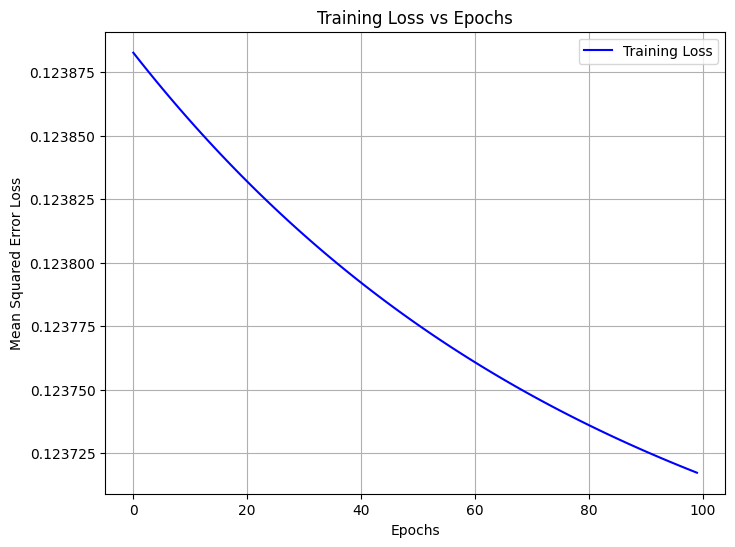

In [ ]:
for i in range(max_epochs):
  # Forward Pass
  X = training_x
  H = np.matmul(X,weights1)
  z = np.array([[sigmoid(x) for x in row] for row in H])
  z = np.hstack((z, np.ones((n,1))))
  O = np.matmul(z,weights2)
  y_hat = np.array([[sigmoid(x) for x in row] for row in O])
  # loss = np.sum((training_y.reshape(-1, 1) - y_hat)**2) / (2 * n)
  loss = (np.mean((training_y.reshape(-1, 1) - y_hat)**2))/2
  trianing_error[i] = loss

  # Back propagation
    # Gradient calculation for weights2
  delta_output = -(training_y.reshape(-1, 1) - y_hat) * grad_sigmoid(O)
  gradient2 = np.dot(z.T, delta_output) / n  # Use z.T instead of Z.T

    # Gradient calculation for weights1
  delta_hidden = np.dot(delta_output, weights2[:-1].T) * grad_sigmoid(H)
  gradient1 = np.dot(X.T, delta_hidden) / n

    # Gradient descent weight updates
  weights2 -= learning_rate * gradient2
  weights1 -= learning_rate * gradient1


# Plotting Training loss vs Epochs
plt.figure(figsize=(8, 6))
plt.plot(range(max_epochs), trianing_error, label='Training Loss', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error Loss')
plt.title('Training Loss vs Epochs')
plt.legend()
plt.grid(True)
plt.savefig("../plots/training_loss_vs_epochs.png")
plt.show()

**2 Classification using the kNearest Neighbors Technique**

**2.1 The Abalone Dataset**

In [66]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
abalone = pd.read_csv(url, header=None)

**2.2 Data PreProcessing and Cleaning**

In [67]:
column_names = ["Sex", "Length", "Diameter", "Height", "Whole weight",
                "Shucked weight", "Viscera weight", "Shell weight", "Rings"]
abalone.columns = column_names

# Removing  the 'Sex' column as it was not directly influence age
abalone = abalone.drop(columns=["Sex"])

**2.3 Training and Test Data**

In [68]:
# Separating the features X and target variable y
X = abalone.drop(columns=["Rings"]).values
y = abalone["Rings"].values

# dividing the dataset into 70% training and 30% test datasets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=333)

**2.4 Implementing the kNearest Neighbors Algorithm**

In [ ]:
# new abalone data as given in the project
new_abalone = np.array([0.569552, 0.446407, 0.154437, 1.016849, 0.439051, 0.222526, 0.291208])

# function for finding eucledean distances
def euclidean_distances(x1, x2):
    return np.linalg.norm(x1 - x2, axis = 1)

distances = euclidean_distances(X_train, new_abalone)

# Sorting the distances and getting the indices of the 3 nearest neighbors
k = 3
nearest_indices = np.argsort(distances)[:k]

# Extracting the corresponding ages (Rings) of the nearest neighbors
nearest_ages = y_train[nearest_indices]

# Predicting the age by finding the mode among the nearest neighbors
from scipy.stats import mode
predicted_age = mode(nearest_ages, keepdims=True)[0][0]

#  printing the predicted age for the new abalone data point
print(f"Predicted age for the new abalone: {predicted_age}")

# computing MSE values
def predict_knn(X_train, y_train, X_test, k):
    k_predictions = []
    for test_point in X_test:

        distances = euclidean_distances(X_train, test_point)

        nearest_indices = np.argsort(distances)[:k]

        nearest_labels = y_train[nearest_indices]

        predicted_label = mode(nearest_labels, keepdims=True)[0][0]

        k_predictions.append(predicted_label)

    return np.array(k_predictions)

# Predicting ages for all test data points using k-NN
predicted_ages_test = predict_knn(X_train, y_train, X_test, 3)

# Computing and printing Mean Squared Error (MSE)
mse = np.mean((predicted_ages_test - y_test) ** 2)
print(f"Mean Squared Error of k-NN with k=3: {mse:.2f}")

Predicted age for the new abalone: 11
Mean Squared Error of k-NN with k=3: 7.65


**2.5 Tuning k to Achieve Optimal Performance**

Optimal value of k: 39
Mean Squared Error for optimal k: 6.37


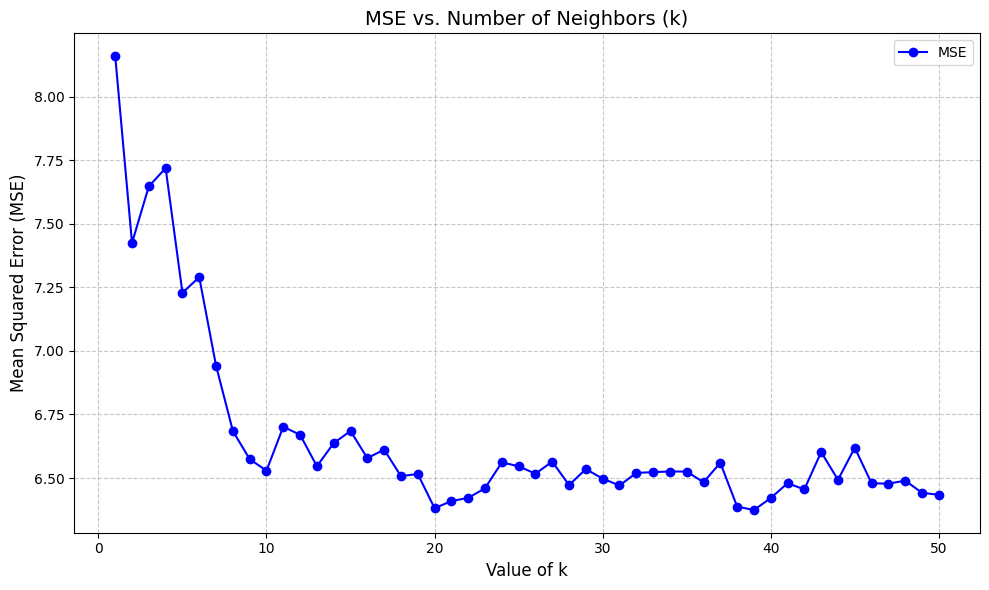

In [ ]:
k_values = range(1, 51)
mse_values = []

for k in k_values:
    # Predicting ages for all test data points using k-NN with current value of k
    y_pred_k = predict_knn(X_train, y_train, X_test, k)

    # Computing Mean Squared Error (MSE)
    mse_k = np.mean((y_pred_k - y_test) ** 2)
    mse_values.append(mse_k)

# Finding optimal k (minimum MSE)
optimal_k = k_values[np.argmin(mse_values)]
optimal_mse = min(mse_values)

# Printing optimal k and its corresponding MSE
print(f"Optimal value of k: {optimal_k}")
print(f"Mean Squared Error for optimal k: {optimal_mse:.2f}")

# Plotting MSE vs. k for visualization performance
plt.figure(figsize=(10, 6))
plt.plot(k_values, mse_values, marker='o', linestyle='-', color='b', label='MSE')
plt.xlabel('Value of k', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.title('MSE vs. Number of Neighbors (k)', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("../plots/mse_vs_neighbors.png")
plt.show()